# 04 · Model Interpretation

Notebook 02 showed *how well* behavior can be predicted. This notebook asks **what the models have learned**:

1. **Which features matter most** for predicting behavior, in Control and in AD mice?
2. **How** do the task conditions and the behavioral history change the predicted behavior?
3. Do Control and AD mice follow **different feature–behavior rules**, or the same rules?

## Predictive, not causal

Everything here describes the **model's** view of the data: which information helps *predict* behavior. A feature that predicts a behavior does not necessarily *cause* it. In this experiment, conditions were also presented in a fixed block order (notebook 01), so condition effects are mixed with experience effects. We therefore say "in long-soft sessions mice stayed home more", not "long distance causes mice to stay home".

## Model used

The **logistic regression on Task + History + Experience** from notebook 02, with regularization fixed at C = 0.1 (the most common choice of the tuning in notebook 02):
* **with class weights** for permutation importance (section 1), so that all four behaviors count equally, as in notebook 02;
* **without class weights** for predicted probabilities (sections 2–3), because only the unweighted model gives honest probabilities (notebook 02, section 8.3).

In [1]:
import sys
sys.path.insert(0, "..")

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import modeling, evaluation
from src import visualization as viz

viz.set_plot_style()
pd.set_option("display.width", 200)
warnings.filterwarnings("ignore", category=UserWarning)

TABLES = "../results/tables"
CLASSES = viz.BEHAVIOR_ORDER

df = pd.read_csv("../data/processed/trials_clean.csv")
data_by_group = {group: df[df["Status"] == group].copy() for group in viz.GROUP_ORDER}

CATEGORICAL = ["Length", "Texture", "SizeCategory", "PrevBehavior"]
NUMERIC = ["TrialInSession", "SessionInCondition"]
FEATURES = CATEGORICAL + NUMERIC


def make_logistic(weighted):
    name = "Logistic regression" if weighted else "Logistic regression (unweighted)"
    model, _ = modeling.make_model(name, CATEGORICAL, NUMERIC)
    model.set_params(classifier__C=0.1)
    return model

## 1. Which features matter most? Permutation importance on held-out mice

**Idea:** if a feature is important, the model should get worse when that feature's information is destroyed. **Permutation importance**:
1. train the model;
2. on **test** data, randomly shuffle one feature column (e.g. `SizeCategory`), which breaks its link with the behavior while keeping its distribution;
3. measure how much the score drops (here: balanced accuracy);
4. repeat the shuffle several times and average.

**Why on held-out mice?** Importance measured on training data shows what the model *memorized*. Measured on new mice, it shows what *generalizes*. We use grouped 5-fold cross-validation (`GroupKFold`): train on ~80 % of the mice, compute importance on the remaining mice, and repeat for all 5 folds.

**Why not the tree-based "feature_importances_"?** Impurity-based importances (as in the original notebook) are computed on the training data and are biased toward features with many categories or numeric values. Permutation importance on held-out data avoids both problems, and it works for any model.

**Note:** each *original* column is shuffled as a whole. `PrevBehavior`, for example, is one-hot encoded into 7 columns inside the pipeline, but it is shuffled as one feature. So we get one importance per *variable*, not per dummy column.

In [2]:
from sklearn.inspection import permutation_importance
from sklearn.model_selection import GroupKFold

importance_rows = []
for group in viz.GROUP_ORDER:
    data = data_by_group[group]
    folds = GroupKFold(n_splits=5).split(data, groups=data["Id"])
    for fold, (train_index, test_index) in enumerate(folds):
        train, test = data.iloc[train_index], data.iloc[test_index]
        model = make_logistic(weighted=True).fit(train[FEATURES], train["Behavior"])
        result = permutation_importance(model, test[FEATURES], test["Behavior"],
                                        scoring="balanced_accuracy", n_repeats=20, random_state=fold)
        for feature, drop in zip(FEATURES, result.importances_mean):
            importance_rows.append({"group": group, "fold": fold, "feature": feature, "importance": drop})

importance = pd.DataFrame(importance_rows)
importance_summary = importance.groupby(["group", "feature"])["importance"].agg(["mean", "std"]).unstack("group")
importance_summary = importance_summary.sort_values(("mean", "Control"), ascending=False)
importance_summary.round(3)

mean            std        
group                  AD Control     AD Control
feature                                         
SizeCategory        0.045   0.103  0.032   0.025
PrevBehavior        0.078   0.048  0.034   0.031
SessionInCondition -0.008   0.008  0.049   0.013
TrialInSession     -0.007   0.006  0.012   0.027
Length              0.064   0.005  0.045   0.016
Texture            -0.037   0.002  0.058   0.011

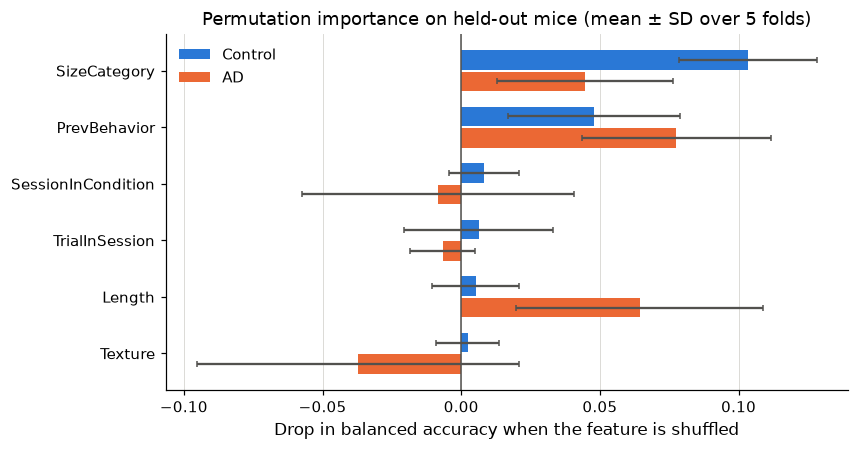

In [3]:
order = importance_summary.index.tolist()
fig, ax = plt.subplots(figsize=(8, 4.2))
height = 0.38
for g_index, group in enumerate(viz.GROUP_ORDER):
    means = [importance_summary.loc[f, ("mean", group)] for f in order]
    stds = [importance_summary.loc[f, ("std", group)] for f in order]
    positions = np.arange(len(order)) + (g_index - 0.5) * height
    ax.barh(positions, means, height=height * 0.9, xerr=stds, color=viz.GROUP_COLORS[group],
            label=group, error_kw={"ecolor": viz.NEUTRAL_DARK, "capsize": 2})
ax.set_yticks(np.arange(len(order)))
ax.set_yticklabels(order)
ax.invert_yaxis()
ax.axvline(0, color=viz.NEUTRAL_DARK, linewidth=1)
ax.set_xlabel("Drop in balanced accuracy when the feature is shuffled")
ax.set_title("Permutation importance on held-out mice (mean ± SD over 5 folds)")
ax.grid(axis="x", color=viz.NEUTRAL_LIGHT)
ax.grid(axis="y", visible=False)
ax.legend()
viz.save_figure(fig, "04_permutation_importance")
plt.show()

**How to read the output:** a bar shows how much balanced accuracy drops on new mice when that feature is shuffled. Larger = more important. Bars near 0 (or negative) mean the feature does not help on new mice.

* **Control mice: pellet size dominates** (drop 0.10), followed by the previous behavior (0.05). Distance, texture and experience contribute almost nothing.
* **AD mice: a different ranking.** The **previous behavior** is most important (0.08), followed by **distance** (0.06) and pellet size (0.045).
  * Distance matters for AD but not for Control. It is the long-distance NoLeave pattern seen in notebooks 01–03.
  * History matters more in AD, as in notebook 02, section 5.
  * Size matters less in AD, consistent with AD mice rarely switching to carrying for large pellets (notebook 03).
* **Texture** has a *negative* importance in AD, with a large spread (SD 0.06). Shuffling it slightly *improved* the score in some folds: the texture effect the model learned from some AD mice did not hold for others. With only 13 mice and 10 of them experiencing hard food, this is noise, not a real effect.

**Caveats:** the spreads (error bars) are large, especially for AD, where each test fold contains only 2–3 mice. Rankings within ~0.03 should not be over-interpreted.

## 2. How do conditions change the predicted behavior?

Logistic-regression coefficients for four classes are hard to read: each class has its own coefficients, and they only make sense relative to each other. A clearer way is to ask the model for **predicted probabilities in specific situations** ("scenarios"):

> "For a mouse at the start of a session (`PrevBehavior = SessionStart`, first trial), in its 3rd session of the block, what is the predicted probability of each behavior in each condition × pellet size?"

We fit one unweighted model per group on **all** mice of that group. To show uncertainty, we refit the model on 200 **bootstrap samples of mice** and take the 2.5–97.5 % range of the predicted probabilities. Resampling mice (not trials) respects the mouse as the unit.

*Note:* these are the model's predictions for one fixed history scenario, not raw averages. They answer "what does the model believe the effect of the condition is, all else equal?"

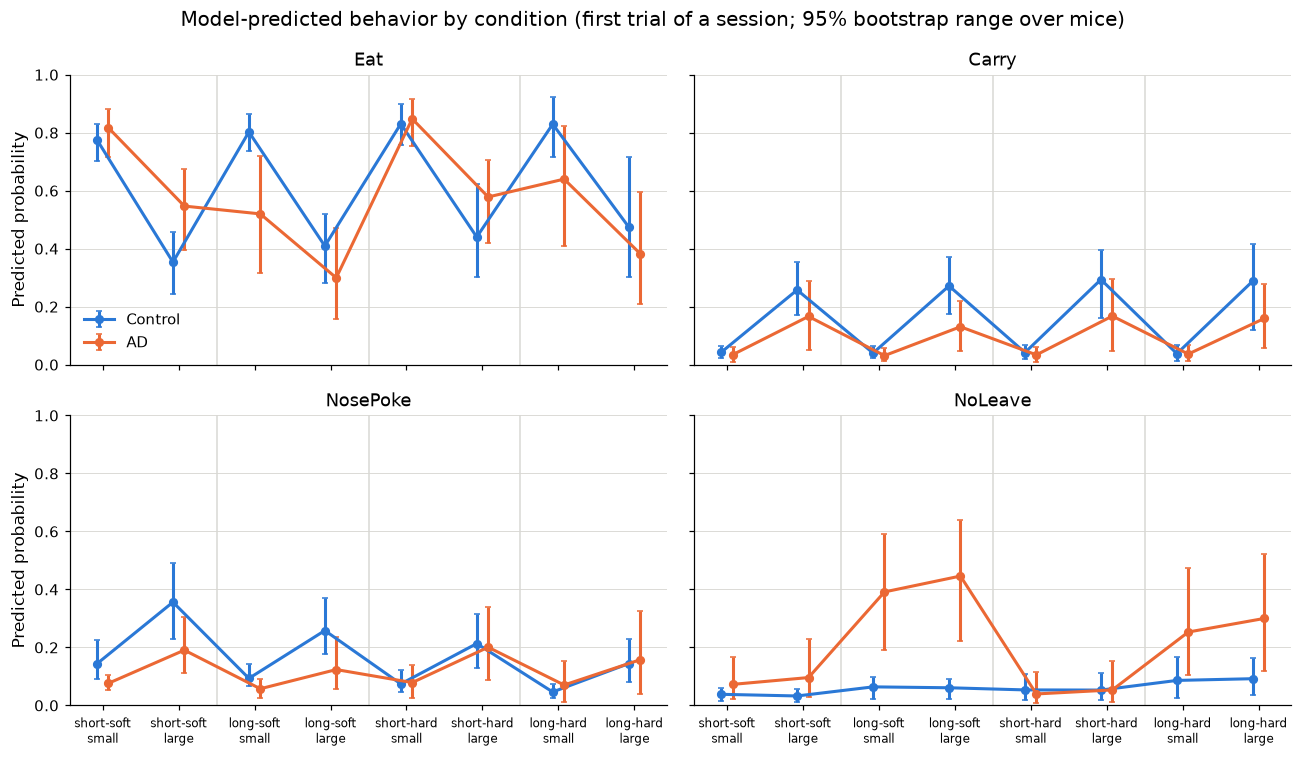

In [4]:
CELLS = [(condition, size) for condition in viz.CONDITION_ORDER for size in viz.SIZE_ORDER]
scenarios = pd.DataFrame({
    "Length": [c.split("-")[0] for c, s in CELLS],
    "Texture": [c.split("-")[1] for c, s in CELLS],
    "SizeCategory": [s for c, s in CELLS],
    "PrevBehavior": "SessionStart",
    "TrialInSession": 1,
    "SessionInCondition": 3,
})
cell_labels = [f"{c}\n{s}" for c, s in CELLS]


def predict_with_bootstrap(data, scenario_table, n_bootstrap=200, seed=0):
    # Point estimate from all mice, plus a bootstrap range over mice.
    model = make_logistic(weighted=False).fit(data[FEATURES], data["Behavior"])
    estimate = pd.DataFrame(model.predict_proba(scenario_table[FEATURES]), columns=model.classes_)[CLASSES]

    rng = np.random.default_rng(seed)
    mice = data["Id"].unique()
    trials_by_mouse = {m: data[data["Id"] == m] for m in mice}
    samples = []
    for _ in range(n_bootstrap):
        sample = pd.concat([trials_by_mouse[m] for m in rng.choice(mice, size=len(mice), replace=True)])
        fitted = make_logistic(weighted=False).fit(sample[FEATURES], sample["Behavior"])
        probabilities = pd.DataFrame(fitted.predict_proba(scenario_table[FEATURES]), columns=fitted.classes_)
        samples.append(probabilities.reindex(columns=CLASSES, fill_value=0).to_numpy())
    samples = np.array(samples)                       # bootstrap x scenario x class
    low = pd.DataFrame(np.quantile(samples, 0.025, axis=0), columns=CLASSES)
    high = pd.DataFrame(np.quantile(samples, 0.975, axis=0), columns=CLASSES)
    return estimate, low, high


condition_predictions = {g: predict_with_bootstrap(data_by_group[g], scenarios) for g in viz.GROUP_ORDER}

fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
for ax, behavior in zip(axes.flat, CLASSES):
    for g_index, group in enumerate(viz.GROUP_ORDER):
        estimate, low, high = condition_predictions[group]
        x = np.arange(len(CELLS)) + (g_index - 0.5) * 0.15
        ax.errorbar(x, estimate[behavior],
                    yerr=[estimate[behavior] - low[behavior], high[behavior] - estimate[behavior]],
                    color=viz.GROUP_COLORS[group], marker="o", markersize=5, linewidth=2, capsize=2, label=group)
    ax.set_title(behavior)
    ax.set_ylim(0, 1)
    for boundary in [1.5, 3.5, 5.5]:
        ax.axvline(boundary, color=viz.NEUTRAL_LIGHT, linewidth=1)
for ax in axes[1]:
    ax.set_xticks(range(len(CELLS)))
    ax.set_xticklabels(cell_labels, fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel("Predicted probability")
axes[0, 0].legend()
fig.suptitle("Model-predicted behavior by condition (first trial of a session; 95% bootstrap range over mice)")
fig.tight_layout()
viz.save_figure(fig, "04_predicted_by_condition")
plt.show()

**How to read the output:** each point is the model's predicted probability for the first trial of a session in that condition; error bars show the uncertainty across resampled sets of mice.

* **Shared pattern (both groups):** large pellets lower the probability of eating on the spot (e.g. Control short-soft: 0.78 → 0.36) and raise Carry and NosePoke. This size effect is the clearest, most consistent relationship in the data.
* **Distance → NoLeave in AD:** the model predicts NoLeave at ~0.4 in long-soft for AD mice vs ~0.06 for Control. The bootstrap ranges do not overlap. In long-hard the AD prediction is also higher (~0.25–0.30) but much more uncertain.
* **Carry for large pellets** is predicted lower for AD (~0.13–0.17 vs ~0.26–0.29), with overlapping ranges.
* The AD error bars are generally wider: fewer mice, and AD mice differ more from each other.

These predictions are close to the raw averages in notebook 01 (section 7), which is reassuring: the model has captured the main condition effects without distorting them. One limitation of this model: logistic regression with only main effects adds the effects of distance, texture and size *independently*. A long-soft-specific effect (e.g. "AD mice react strongly to the first change of distance") can only be approximated.

## 3. How does the previous trial change the predicted behavior?

Same approach, but now we vary `PrevBehavior` and keep the condition fixed (**short-soft, large pellet**, 2nd trial of a session, 3rd session of the block). The `SessionStart` row is the "no history" reference.

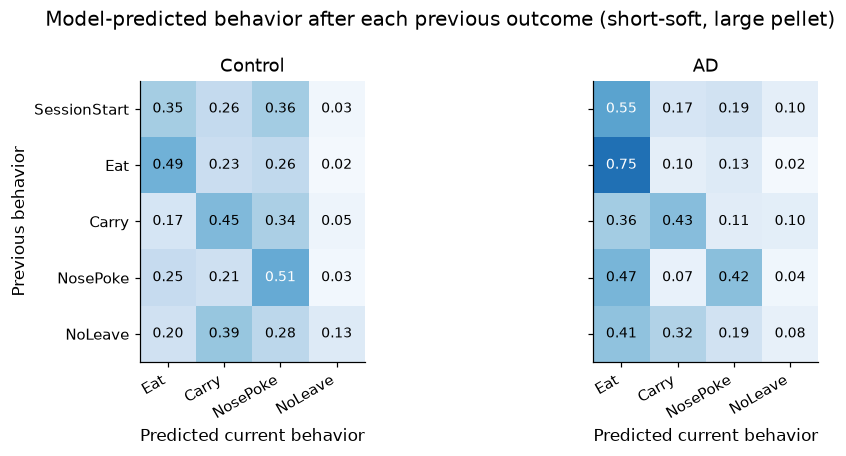

Control
                            Eat              Carry           NosePoke            NoLeave
SessionStart  0.35 [0.23, 0.47]  0.26 [0.17, 0.34]  0.36 [0.24, 0.51]  0.03 [0.01, 0.07]
Eat           0.49 [0.35, 0.59]  0.23 [0.15, 0.31]  0.26 [0.17, 0.39]  0.02 [0.01, 0.06]
Carry         0.17 [0.11, 0.25]  0.45 [0.29, 0.55]  0.34 [0.21, 0.49]  0.05 [0.02, 0.09]
NosePoke      0.25 [0.17, 0.34]  0.21 [0.11, 0.31]  0.51 [0.39, 0.63]  0.03 [0.01, 0.09]
NoLeave       0.20 [0.12, 0.31]  0.39 [0.20, 0.57]  0.28 [0.19, 0.42]  0.13 [0.02, 0.31]

AD
                            Eat              Carry           NosePoke            NoLeave
SessionStart  0.55 [0.38, 0.68]  0.17 [0.04, 0.32]  0.19 [0.09, 0.31]  0.10 [0.02, 0.27]
Eat           0.75 [0.62, 0.84]  0.10 [0.03, 0.18]  0.13 [0.07, 0.21]  0.02 [0.01, 0.04]
Carry         0.36 [0.26, 0.55]  0.43 [0.07, 0.58]  0.11 [0.05, 0.35]  0.10 [0.03, 0.28]
NosePoke      0.47 [0.39, 0.56]  0.07 [0.03, 0.13]  0.42 [0.30, 0.52]  0.04 [0.01, 0.09]
NoLeave  

In [5]:
previous_options = ["SessionStart", "Eat", "Carry", "NosePoke", "NoLeave"]
history_scenarios = pd.DataFrame({
    "Length": "short", "Texture": "soft", "SizeCategory": "large",
    "PrevBehavior": previous_options,
    "TrialInSession": [1, 2, 2, 2, 2],     # SessionStart can only be the first trial
    "SessionInCondition": 3,
})
history_predictions = {g: predict_with_bootstrap(data_by_group[g], history_scenarios, seed=1)
                       for g in viz.GROUP_ORDER}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for ax, group in zip(axes, viz.GROUP_ORDER):
    estimate, low, high = history_predictions[group]
    ax.imshow(estimate.values, cmap="Blues", vmin=0, vmax=1)
    for i in range(len(previous_options)):
        for j in range(len(CLASSES)):
            value = estimate.values[i, j]
            ax.text(j, i, f"{value:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if value > 0.5 else "black")
    ax.set_xticks(range(len(CLASSES)))
    ax.set_xticklabels(CLASSES, rotation=30, ha="right")
    ax.set_yticks(range(len(previous_options)))
    ax.set_yticklabels(previous_options)
    ax.set_xlabel("Predicted current behavior")
    ax.set_title(group)
    ax.grid(False)
axes[0].set_ylabel("Previous behavior")
fig.suptitle("Model-predicted behavior after each previous outcome (short-soft, large pellet)")
fig.tight_layout()
viz.save_figure(fig, "04_predicted_by_history")
plt.show()

for group in viz.GROUP_ORDER:
    estimate, low, high = history_predictions[group]
    table = estimate.copy()
    for behavior in CLASSES:
        table[behavior] = [f"{e:.2f} [{l:.2f}, {h:.2f}]" for e, l, h in zip(estimate[behavior], low[behavior], high[behavior])]
    table.index = previous_options
    print(group)
    print(table.to_string())
    print()

**How to read the output:** each row shows the predicted behavior after a given previous outcome (short-soft, large pellet). Compare each row with the `SessionStart` row.

* **Behaviors persist in both groups.** After Carry, Carry is much more likely (Control 0.45, AD 0.43, vs 0.26 / 0.17 at session start). After NosePoke, NosePoke is more likely (0.51 / 0.42 vs 0.36 / 0.19).
* **AD mice return to eating more strongly.** After an Eat trial, AD mice are predicted to eat again with probability 0.75 vs 0.49 for Control. After a NosePoke, AD mice almost never carry next (0.07 vs 0.21).
* **AD mice are more likely to start a session with NoLeave** (0.10 vs 0.03).
* Ranges are wide for rare previous behaviors (e.g. after NoLeave), because few trials follow them.

**Interpretation:** these are *sequential dependencies*, not proof of a "memory" of the previous trial. Part of the persistence can come from the mouse's current state (hunger, arousal) or from stable differences between mice (a mouse that often carries has many Carry → Carry transitions).

## 4. Do Control and AD mice follow different rules?

Sections 2–3 show differences between the two groups' models. But are these differences **reliable enough to improve predictions for new mice**? We compare three models, all evaluated with leave-one-mouse-out over all 41 mice:

| Model | Trained on | What it assumes |
|---|---|---|
| **A. Shared** | all other mice, group ignored | both groups follow the same rules |
| **B. Shared + group** | all other mice, with `Status` as an extra feature | same rules, but each group has its own *baseline* tendency for each behavior |
| **C. Separate** | only other mice of the same group (as in notebook 02) | every relationship can differ between groups |

**Logic:** if B predicts better than A, the groups differ in baseline tendencies. If C predicts better than B, the *relationships themselves* differ (a different effect of size, distance or history).

**Metric:** log loss of the unweighted model (lower = better), computed separately for Control and AD mice, compared with a paired bootstrap over mice. Log loss is the most sensitive metric here because it uses the full predicted probabilities, not just the final answer.

*Caveat:* model C is trained on fewer mice than A and B (12 or 27 instead of 40). If the groups truly followed the same rules, C would be slightly worse purely because of less training data.

In [6]:
unweighted = make_logistic(weighted=False)
with_status, _ = modeling.make_model("Logistic regression (unweighted)", CATEGORICAL + ["Status"], NUMERIC)
with_status.set_params(classifier__C=0.1)

predictions_A = evaluation.leave_one_mouse_out(unweighted, {}, df, FEATURES, "Behavior", CLASSES)
predictions_B = evaluation.leave_one_mouse_out(with_status, {}, df, FEATURES + ["Status"], "Behavior", CLASSES)
predictions_C = pd.concat([
    evaluation.leave_one_mouse_out(unweighted, {}, data_by_group[g], FEATURES, "Behavior", CLASSES)
    for g in viz.GROUP_ORDER]).sort_index()

model_predictions = {"A. Shared": predictions_A, "B. Shared + group": predictions_B, "C. Separate": predictions_C}
rule_rows = []
for group in viz.GROUP_ORDER:
    mice = data_by_group[group]["Id"].unique()
    for name, predictions in model_predictions.items():
        row = {"tested on": group, "model": name}
        row.update(evaluation.summary_metrics(predictions[predictions["Id"].isin(mice)], CLASSES))
        rule_rows.append(row)
rule_table = pd.DataFrame(rule_rows)
rule_table.round(4)

,tested on,model,balanced_accuracy,macro_F1,log_loss
0,Control,A. Shared,0.3258,0.3213,0.9667
1,Control,B. Shared + group,0.3241,0.3154,0.9719
2,Control,C. Separate,0.3253,0.3198,0.9722
3,AD,A. Shared,0.3376,0.3404,0.9365
4,AD,B. Shared + group,0.3304,0.3390,0.9543
5,AD,C. Separate,0.3326,0.3437,0.9398


In [7]:
comparison_rows = []
for group in viz.GROUP_ORDER:
    mice = data_by_group[group]["Id"].unique()
    for name_a, name_b in [("A. Shared", "B. Shared + group"), ("B. Shared + group", "C. Separate")]:
        a = model_predictions[name_a]
        b = model_predictions[name_b]
        diff = evaluation.paired_bootstrap_difference(a[a["Id"].isin(mice)], b[b["Id"].isin(mice)],
                                                      CLASSES, metric="log_loss", n_bootstrap=1000)
        comparison_rows.append({
            "tested on": group, "comparison": f"{name_b}  vs  {name_a}",
            "change in log loss": diff.mean(),
            "95% CI": f"[{np.quantile(diff, 0.025):+.4f}, {np.quantile(diff, 0.975):+.4f}]",
            "fraction of bootstraps where it improves": (diff < 0).mean(),
        })
pd.DataFrame(comparison_rows).round(4)

,tested on,comparison,change in log loss,95% CI,fraction of bootstraps where it improves
0,Control,B. Shared + group vs A. Shared,0.0059,"[-0.0092, +0.0250]",0.255
1,Control,C. Separate vs B. Shared + group,0.0001,"[-0.0139, +0.0155]",0.493
2,AD,B. Shared + group vs A. Shared,0.0163,"[-0.0193, +0.0619]",0.230
3,AD,C. Separate vs B. Shared + group,-0.0141,"[-0.0426, +0.0161]",0.816


**How to read the output:**
* **Adding the group label (B vs A) does not help:** log loss changes by +0.006 (Control) and +0.016 (AD). Both CIs include 0, and the change is in the *wrong* direction (higher = worse).
* **Separate models (C vs B) do not reliably help either:** no change for Control (0.000), a small, uncertain improvement for AD (−0.014, CI −0.043 to +0.016; better in 82 % of bootstrap samples).
* The **shared model A** is as good as any model for new mice, in both groups.

**How does this fit with section 1, where distance mattered for AD but not for Control?** Three reasons:
1. **Heterogeneity within AD.** The long-distance NoLeave pattern is shown strongly by about 6 of 10 AD mice (notebook 03). For a new AD mouse that does *not* show it, an AD-specific model predicts too much NoLeave and is penalized. Across mice, the gains and losses largely cancel.
2. **Different metrics.** Balanced accuracy (section 1) gives the rare NoLeave class the same weight as Eat, so a NoLeave pattern matters a lot. Log loss is dominated by the frequent classes, where both groups behave similarly.
3. **Less training data for model C**, as noted above.

**Conclusion:** at the level of **single trials of new mice**, Control and AD mice follow **largely the same rules**: the same size effect and the same tendency to repeat behaviors. Their differences (NoLeave at long distance, less carrying, stronger return to eating) are real at the group level (notebooks 01, 03; sections 2–3 here). But they are expressed by a subset of AD mice, so they do not make the trial-by-trial behavior of a *new* AD mouse more predictable. In short: **the differences are better described as differences between animals than as a different decision rule for the whole group.**

## 5. Save results

In [8]:
importance_summary.round(4).to_csv(f"{TABLES}/04_permutation_importance.csv")
rule_table.round(4).to_csv(f"{TABLES}/04_shared_vs_separate_models.csv", index=False)
print("Saved.")

Saved.


## 6. Summary: what the models learned, and what the whole project shows

### What the behavior models learned
* **Pellet size** is the most important and most consistent predictor in both groups: large pellets shift behavior from eating on the spot toward carrying and nose-poking.
* **The previous trial** is the second key predictor, and it is more important in AD mice. Behaviors persist from trial to trial, and AD mice return to eating more strongly.
* **Distance** matters for AD mice (mainly through NoLeave in long-distance sessions) but hardly for Control mice.
* **Texture and experience** add little that generalizes to new mice.
* **Shared vs separate rules:** a single shared model predicts new mice as well as group-specific models. The group differences are carried by a subset of AD animals rather than by a different rule for every AD mouse.

### The project in five findings
1. **Behavior is partly predictable before the trial** (balanced accuracy ~0.45–0.50, chance 0.25), mainly from pellet size and the previous outcome. Large differences between individual mice limit any model (notebook 02).
2. **Simple models are enough.** Random forests and gradient boosting did not beat regularized logistic regression on these few, mostly categorical predictors (notebook 02).
3. **Genotype is not visible in *overall* behavior** (AUC 0.50) **but is visible in *how* behavior changes with the task.** The increase of NoLeave with distance identifies AD mice with AUC 0.81 (notebook 03).
4. **AD-associated behavioral profile:** more eating on the spot, little carrying and no size-dependent switch to carrying, stopping foraging when the distance increases, fewer back-and-forth trips, less variable choices. These patterns fit hypotheses of altered **cost sensitivity** and reduced **behavioral variability**, which future experiments would need to test.
5. **Heterogeneity:** several AD effects come from a subset of AD mice (e.g. 6 of 10 react strongly to distance). This is visible in every notebook and is itself a scientifically interesting result.

### Predictive vs causal
All results are **associations learned by predictive models**. They show *which* behavioral measures differ and *which* information predicts behavior, not *why*. In particular:
* conditions were presented in a fixed block order, so condition effects are mixed with experience and with reactions to the *change* of condition;
* the AD mice are a genetic model, and many biological differences (not only amyloid pathology) could underlie the behavioral differences;
* movement-based group differences may partly reflect *when and how* the control mice were tested (notebook 03, limitations).

### Methodological take-aways
* The **mouse** is the independent unit: validate on held-out mice and summarize per mouse for group questions.
* Keep **predictors that exist before the decision** separate from measurements of the behavior itself.
* Report **uncertainty** (bootstrap over mice, permutation tests), especially with 13 AD mice.
* **Interpret with care:** permutation importance on held-out data, predicted probabilities for concrete scenarios, and explicit comparisons of shared vs group-specific models.